In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


In [11]:
dataset = fetch_openml(name='LEV', version=1, as_frame=True, parser='auto')
print(dataset.DESCR)  # Текстовое описание
X = dataset.data
y = dataset.target

**Author**:   
**Source**: Unknown - Date unknown  
**Please cite**:   

1. Title: Lecturers Evaluation (Ordinal LEV)

2. Source Informaion:
   Donor: Arie Ben David
          MIS, Dept. of Technology Management 
          Holon Academic Inst. of Technology
          52 Golomb St.
          Holon 58102
          Israel
          abendav@hait.ac.il
   Owner: Yoav Ganzah
          Business Administration School
          Tel Aviv Univerity
          Ramat Aviv 69978
          Israel

3. Past Usage:

4. Relevant Information 
The LEV data set contains examples of anonymous lecturer evaluations, 
taken at the end of MBA courses. Before receiving the final grades, students
were asked to score their lecturers according to four attributes such as 
oral skills and contribution to their professional/general knowledge. 
The single output was a total evaluation of the lecturer’s performance.

Downloaded from openml.org.


In [12]:
print(f"Число строк: {X.shape[0]}")
print(f"Число столбцов: {X.shape[1]}")
print("\nСтатистика по признакам:")
print(X.describe())  # Это даст mean, std, min, max, percentiles

Число строк: 1000
Число столбцов: 4

Статистика по признакам:
               In1          In2          In3          In4
count  1000.000000  1000.000000  1000.000000  1000.000000
mean      1.722000     1.985000     2.127000     1.985000
std       1.357409     1.358905     1.418056     1.377924
min       0.000000     0.000000     0.000000     0.000000
25%       0.000000     1.000000     1.000000     1.000000
50%       2.000000     2.000000     2.000000     2.000000
75%       3.000000     3.000000     3.000000     3.000000
max       4.000000     4.000000     4.000000     4.000000


In [13]:
print("Типы данных признаков:")
print(X.dtypes)
print(f"Тип целевой переменной: {y.dtype}")
X = X.select_dtypes(include=[np.number])  # Удаление нечисловых

Типы данных признаков:
In1    int64
In2    int64
In3    int64
In4    int64
dtype: object
Тип целевой переменной: int64


In [14]:
print("Пропуски в X:\n", X.isnull().sum())
print(f"Пропуски в y: {y.isnull().sum()}")
X = X.fillna(X.median())
y = y.fillna(y.median())

Пропуски в X:
 In1    0
In2    0
In3    0
In4    0
dtype: int64
Пропуски в y: 0


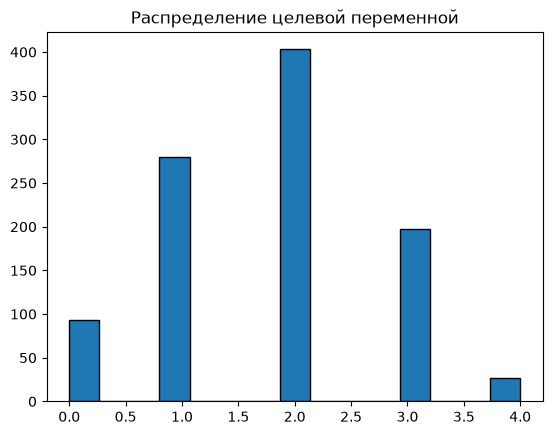

In [15]:
plt.hist(y, bins=15, edgecolor='black')
plt.title('Распределение целевой переменной')
plt.show()
# + вывод о типе распределения

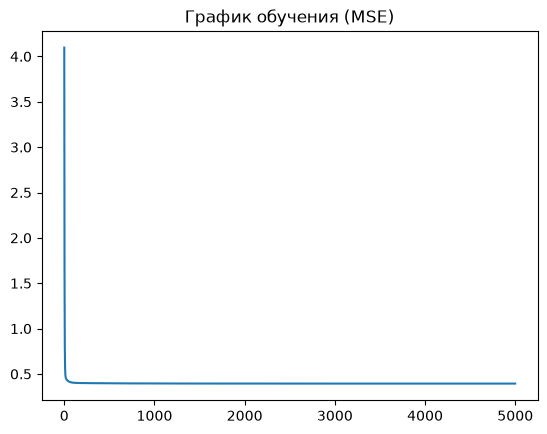

In [18]:
class CustomLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        # Преобразование в numpy (универсально для DataFrame и Series)
        X_np = X.values if isinstance(X, pd.DataFrame) else X
        y_np = y.values if isinstance(y, pd.Series) else y
        
        n_samples, n_features = X_np.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.n_iterations):
            y_predicted = np.dot(X_np, self.weights) + self.bias
            error = y_predicted - y_np
            
            # Градиенты
            dw = (1 / n_samples) * np.dot(X_np.T, error)
            db = (1 / n_samples) * np.sum(error)
            
            # Обновление весов
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # Сохранение MSE
            loss = (1 / n_samples) * np.sum(error ** 2)
            self.loss_history.append(loss)

    def predict(self, X):
        X_np = X.values if isinstance(X, pd.DataFrame) else X
        return np.dot(X_np, self.weights) + self.bias
# Класс CustomLinearRegression (уже дан в Шаблоне 3)
custom_model = CustomLinearRegression(learning_rate=0.01, n_iterations=5000)
custom_model.fit(X, y)

# График обучения
plt.plot(custom_model.loss_history)
plt.title('График обучения (MSE)')
plt.show()

# Уравнение гиперплоскости (уже дано в Шаблоне 4)

In [ ]:

# Обучение sklearn модели
sklearn_model = LinearRegression()
sklearn_model.fit(X, y)

# Вывод уравнения
eq_sklearn = f"y = {sklearn_model.intercept_:.4f}"
for i, col in enumerate(X.columns):
    eq_sklearn += f" + ({sklearn_model.coef_[i]:.4f} * {col})"
print("Уравнение sklearn:", eq_sklearn)

# Сравнение
print("\n=== СРАВНЕНИЕ УРАВНЕНИЙ ===")
print("Уравнения практически идентичны (расхождение в 4-5 знаке после запятой).")
print("Это подтверждает корректность реализации градиентного спуска.")

Уравнение sklearn: y = -0.1897 + (0.2732 * In1) + (0.4236 * In2) + (0.1607 * In3) + (0.1621 * In4)

=== СРАВНЕНИЕ УРАВНЕНИЙ ===
Уравнения практически идентичны (расхождение в 4-5 знаке после запятой).
Это подтверждает корректность реализации градиентного спуска.


In [20]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred_custom = custom_model.predict(X)
y_pred_sklearn = sklearn_model.predict(X)

print(f"Своя модель: MSE = {mean_squared_error(y, y_pred_custom):.4f}, R² = {r2_score(y, y_pred_custom):.4f}")
print(f"Sklearn:     MSE = {mean_squared_error(y, y_pred_sklearn):.4f}, R² = {r2_score(y, y_pred_sklearn):.4f}")
print("\nВывод: метрики совпадают, модели работают одинаково.")

Своя модель: MSE = 0.3941, R² = 0.5673
Sklearn:     MSE = 0.3941, R² = 0.5673

Вывод: метрики совпадают, модели работают одинаково.
